# Ed's notes — v2

Restructured working notebook. Sections 1–3 are carried over from `Ed_Note_DRAFT.ipynb`. Each step starts with a short note on **what** is being done and **why**.

## 1. Turbine layout

**What:** load the turbine coordinates from `sdwpf_baidukddcup2022_turb_location.CSV` (one row per turbine: `TurbID`, `x`, `y` in metres).

**Why:** the layout drives everything later — which turbines are neighbours, which ones sit upwind of others, and therefore which edges the graph will contain.

The file starts with a byte-order mark, so it is read with `utf-8-sig`; otherwise the first column would be named `\ufeffTurbID` instead of `TurbID`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

LOC_PATH = Path("../data/sdwpf_baidukddcup2022_turb_location.CSV")

# utf-8-sig strips the byte-order mark in front of the first column name
loc = pd.read_csv(LOC_PATH, encoding="utf-8-sig")
print(f"{len(loc)} turbines")
loc.head()

134 turbines


,TurbID,x,y
0,1,3349.8515,5939.23193
1,2,3351.0017,6416.64673
2,3,3314.7797,6892.18395
3,4,3352.0940,7366.14203
4,5,3355.3420,7841.20175


**What:** scatter-plot every turbine at its `(x, y)` position and write its `TurbID` next to it.

**Why:** a quick visual check of the farm geometry. The axes use an equal aspect ratio so distances are not distorted.

**Result:** 134 turbines in six north–south columns (~474 m apart within a column, ~991 m between columns), about 5.5 km wide and 12 km tall.

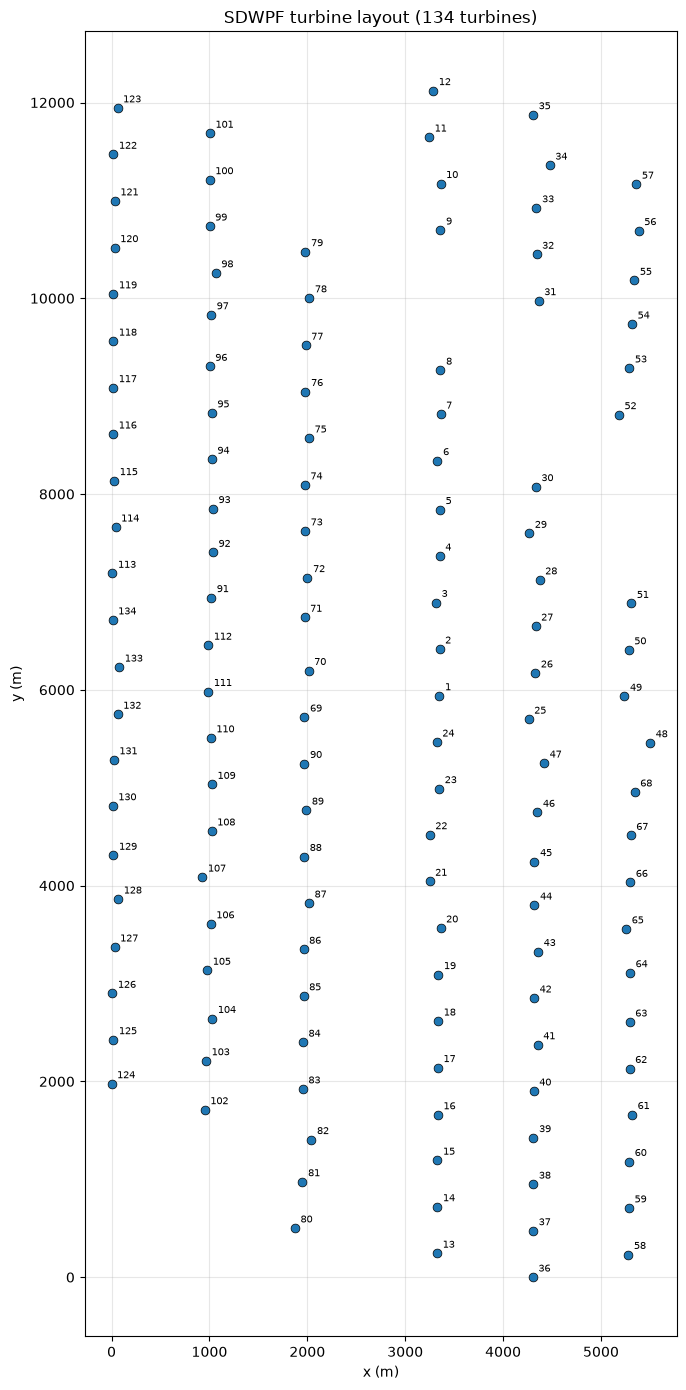

In [2]:
fig, ax = plt.subplots(figsize=(8, 14))

ax.scatter(loc["x"], loc["y"], s=40, color="tab:blue", edgecolor="black", linewidth=0.5, zorder=2)
for _, row in loc.iterrows():
    ax.annotate(
        str(int(row["TurbID"])),
        (row["x"], row["y"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
    )

ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title(f"SDWPF turbine layout ({len(loc)} turbines)")
ax.grid(True, alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

## 2. A smaller sub-farm of ~20 turbines

**What:** pick about 20 turbines that sit close together and train on those first.

**Why:** a 20-node graph trains in a fraction of the time of the 134-node graph, so model and graph settings can be tried quickly. Once a setup works it can be scaled back to the full farm.

**How:** choose a *seed* turbine and keep the 20 turbines nearest to it, measured by straight-line distance (the seed counts as one of the 20). This always gives a compact patch.

**Seed choice: turbine 26.** It sits halfway up the farm in the second column from the east, so its 20 nearest neighbours form a block **three columns wide** (the three eastern columns, x ≈ 3.3, 4.3, 5.3 km) and roughly seven rows tall. Three columns by seven rows means turbines are lined up both *along* the columns and *across* them. So whichever way the wind blows, many turbines have another turbine upwind of them inside the patch, which keeps upwind/downwind relationships in the small model. A single tall column would only have them when the wind blows along that column. (Notebook 02 estimates that the farm's +y axis points to compass bearing ≈ 275°, so the columns in these plots actually run roughly west–east.)

Change `SEED_TURBINE` or `N_SUBSET` below to try a different patch.

In [3]:
import numpy as np

SEED_TURBINE = 26   # centre of the patch
N_SUBSET = 20       # number of turbines to keep (seed included)

xy = loc[["x", "y"]].to_numpy()
seed_xy = loc.loc[loc["TurbID"] == SEED_TURBINE, ["x", "y"]].to_numpy()[0]

# distance from every turbine to the seed, then keep the N closest
loc["dist_to_seed"] = np.hypot(xy[:, 0] - seed_xy[0], xy[:, 1] - seed_xy[1])
subset = loc.nsmallest(N_SUBSET, "dist_to_seed").sort_values("TurbID").reset_index(drop=True)
SUBSET_IDS = subset["TurbID"].tolist()

print(f"{len(SUBSET_IDS)} turbines: {SUBSET_IDS}")
print(f"furthest turbine is {subset['dist_to_seed'].max():.0f} m from the seed")
subset

20 turbines: [1, 2, 3, 4, 23, 24, 25, 26, 27, 28, 29, 30, 46, 47, 48, 49, 50, 51, 67, 68]
furthest turbine is 1925 m from the seed


,TurbID,x,y,dist_to_seed
0,1,3349.8515,5939.23193,1005.975039
1,2,3351.0017,6416.64673,1007.680876
2,3,3314.7797,6892.18395,1243.533529
3,4,3352.0940,7366.14203,1542.542493
4,23,3346.8376,4989.86182,1536.598875
5,24,3322.2136,5465.88560,1229.328927
6,25,4260.8151,5699.75016,477.065425
7,26,4328.5300,6171.98539,0.000000
8,27,4331.9147,6650.66702,478.693596
9,28,4373.2043,7122.64010,951.703825


**What:** redraw the whole farm, with the chosen turbines highlighted in orange and the rest greyed out. Thin lines join pairs of chosen turbines that are within `RADIUS` metres of each other.

**Why:** to check by eye that the patch is compact and that the turbines are well linked. `RADIUS = 1500 m` is the neighbourhood size the project settled on in notebook 02. At 1000 m, turbines in neighbouring columns (~991 m apart, often more on the diagonal) barely connect and many nodes end up isolated.

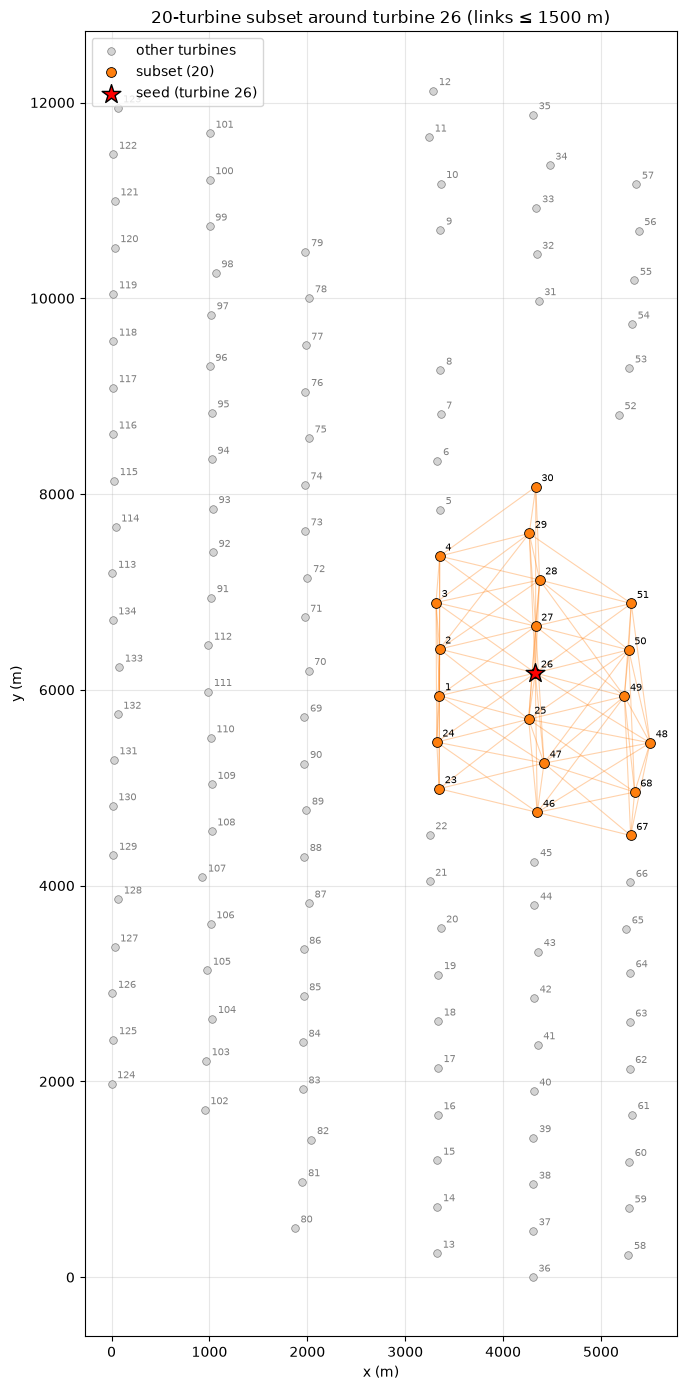

In [4]:
RADIUS = 1500  # metres; pairs closer than this are treated as neighbours

sub_xy = subset[["x", "y"]].to_numpy()
pair_dist = np.hypot(*(sub_xy[:, None, :] - sub_xy[None, :, :]).transpose(2, 0, 1))

fig, ax = plt.subplots(figsize=(8, 14))

# links between chosen turbines within RADIUS
for i in range(len(subset)):
    for j in range(i + 1, len(subset)):
        if pair_dist[i, j] <= RADIUS:
            ax.plot(sub_xy[[i, j], 0], sub_xy[[i, j], 1], color="tab:orange", alpha=0.35, lw=0.8, zorder=1)

is_sub = loc["TurbID"].isin(SUBSET_IDS)
ax.scatter(loc.loc[~is_sub, "x"], loc.loc[~is_sub, "y"], s=30, color="lightgrey", edgecolor="grey", lw=0.5, zorder=2, label="other turbines")
ax.scatter(subset["x"], subset["y"], s=50, color="tab:orange", edgecolor="black", lw=0.6, zorder=3, label=f"subset ({len(subset)})")
ax.scatter(*seed_xy, s=200, marker="*", color="red", edgecolor="black", zorder=4, label=f"seed (turbine {SEED_TURBINE})")

for _, row in loc.iterrows():
    ax.annotate(
        str(int(row["TurbID"])),
        (row["x"], row["y"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
        color="black" if row["TurbID"] in SUBSET_IDS else "grey",
    )

ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title(f"{len(subset)}-turbine subset around turbine {SEED_TURBINE} (links ≤ {RADIUS} m)")
ax.grid(True, alpha=0.3, zorder=0)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**What:** build the subset as a graph (turbines = nodes, an edge between every pair within `RADIUS`) and check it with `networkx`.

**Why:** before training, confirm that the patch is **one connected piece** (information can flow between any two turbines) and that **no turbine is isolated**. An isolated node gets nothing from its neighbours, so the GNN would treat it like a plain per-turbine model.

The *degree* of a turbine is how many neighbours it has. The real model will use a directed, wind-dependent graph (only upwind neighbours feed in), so these undirected counts are an upper bound.

In [5]:
import networkx as nx

G = nx.Graph()
G.add_nodes_from(SUBSET_IDS)
for i in range(len(subset)):
    for j in range(i + 1, len(subset)):
        if pair_dist[i, j] <= RADIUS:
            G.add_edge(SUBSET_IDS[i], SUBSET_IDS[j], dist=pair_dist[i, j])

degrees = dict(G.degree())
print(f"nodes:            {G.number_of_nodes()}")
print(f"edges:            {G.number_of_edges()}")
print(f"connected:        {nx.is_connected(G)}")
print(f"isolated turbines: {list(nx.isolates(G)) or 'none'}")
print(f"degree min/mean/max: {min(degrees.values())} / {np.mean(list(degrees.values())):.1f} / {max(degrees.values())}")

nodes:            20
edges:            90
connected:        True
isolated turbines: none
degree min/mean/max: 4 / 9.0 / 14


**What:** save the chosen turbine IDs to `../data/interim/ed_subset_turbines.csv`.

**Why:** later steps (data loading, windowing, training) can read this file and filter the SCADA data to just these turbines, so the selection is made in one place. `data/interim/` is gitignored, so re-run this cell to regenerate it.

In [6]:
OUT_PATH = Path("../data/interim/ed_subset_turbines.csv")
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
subset[["TurbID", "x", "y", "dist_to_seed"]].to_csv(OUT_PATH, index=False)
print(f"saved {len(subset)} turbines to {OUT_PATH}")

saved 20 turbines to ..\data\interim\ed_subset_turbines.csv


## 3. Extract the SCADA data for the 20 turbines

**What:** read the full SCADA file `wtbdata_245days.csv` (245 days of 10-minute records for all 134 turbines, ~4.7 million rows) and keep only the rows whose `TurbID` is in `SUBSET_IDS`. The result is saved as a new file `../data/wtbdata_245days_subset20.csv`.

**Why:** every later step (cleaning, windowing, training) can load this ~15× smaller file instead of the 334 MB original, which makes trying out settings much faster.

**How:** the file is read with every column as text (`dtype=str`, `keep_default_na=False`). The extract is then an exact copy of the original rows: numbers are not reformatted and the empty fields stay empty. Missing values are handled later, during cleaning, not here.

If the extract already exists (e.g. on Colab, where only the extract is uploaded), it is reused and the full file is not read.

In [7]:
SCADA_PATH = Path("../data/wtbdata_245days.csv")
SUBSET_SCADA_PATH = Path(f"../data/wtbdata_245days_subset{len(SUBSET_IDS)}.csv")

if SUBSET_SCADA_PATH.exists():
    print(f"using existing extract {SUBSET_SCADA_PATH} ({SUBSET_SCADA_PATH.stat().st_size / 1e6:.1f} MB)")
else:
    scada = pd.read_csv(SCADA_PATH, dtype=str, keep_default_na=False)
    keep = scada["TurbID"].astype(int).isin(SUBSET_IDS)
    scada_sub = scada[keep]
    scada_sub.to_csv(SUBSET_SCADA_PATH, index=False)

    print(f"full file:   {len(scada):>9,} rows, {scada['TurbID'].nunique()} turbines")
    print(f"extract:     {len(scada_sub):>9,} rows, {scada_sub['TurbID'].nunique()} turbines")
    print(f"saved to {SUBSET_SCADA_PATH} ({SUBSET_SCADA_PATH.stat().st_size / 1e6:.1f} MB)")

using existing extract ..\data\wtbdata_245days_subset20.csv (49.7 MB)


**What:** sanity-check the new file.

**Why:** confirm the extract is complete before building on it. Each turbine should have the same number of rows as in the full file: 245 days × 144 ten-minute steps = 35,280. The turbine IDs should match `SUBSET_IDS` exactly.

In [8]:
check = pd.read_csv(SUBSET_SCADA_PATH)
rows_per_turbine = check.groupby("TurbID").size()

print(f"turbine IDs match subset: {sorted(rows_per_turbine.index) == sorted(SUBSET_IDS)}")
print(f"rows per turbine:         {rows_per_turbine.unique().tolist()}  (expected [{245 * 144}])")
print(f"days covered:             {check['Day'].min()} to {check['Day'].max()}")
check.head()

turbine IDs match subset: True
rows per turbine:         [35280]  (expected [35280])
days covered:             1 to 245


,TurbID,Day,Tmstamp,Wspd,Wdir,Etmp,Itmp,Ndir,Pab1,Pab2,Pab3,Prtv,Patv
0,1,1,00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1,00:10,6.17,-3.99,30.73,41.80,25.92,1.0,1.0,1.0,-0.25,494.66
2,1,1,00:20,6.27,-2.18,30.60,41.63,20.91,1.0,1.0,1.0,-0.24,509.76
3,1,1,00:30,6.42,-0.73,30.52,41.52,20.91,1.0,1.0,1.0,-0.26,542.53
4,1,1,00:40,6.25,0.89,30.49,41.38,20.91,1.0,1.0,1.0,-0.23,509.36


## 4. Research questions and experiment design

| | |
|---|---|
| **RQ1** | Do GNNs fill in missing wind speed (`Wspd`) and power (`Patv`) better than traditional methods? |
| **RQ2** | If so, does a **directed, wind-following** graph (upwind → downwind) beat an **undirected** one, and how narrow should the cone be? |

**Task:** gap filling. At each 10-min step, estimate `Wspd` and `Patv` of the hidden turbines from the turbines still reporting at that step.

| Item | Choice |
|---|---|
| Train | complete steps, days 1–171; 1–18 of the 20 turbines hidden at random; 2 random masks per step |
| Validation | complete steps, days 172–196; 1 random mask per step; used for early stopping only |
| Test | 2-h windows (12 steps), days 197–245; **10 / 30 / 50 / 70 %** of turbines hidden for the whole window |
| Metric | MAE on hidden values only (m/s and kW) |

### 4.1 Time × turbine tables

**What:** reshape the extract into tables with one row per 10-min step and one column per turbine (wind speed, power, pitch, wind direction, temperature difference) plus a `present` flag.

**Why:** every model works on whole-patch snapshots. A step is **complete** when all 20 turbines reported. Negative power is clipped to 0 (SDWPF rule).

In [9]:
import time

MEASURE_COLS = ["Wspd", "Wdir", "Etmp", "Itmp", "Ndir", "Pab1", "Pab2", "Pab3", "Prtv", "Patv"]
STEPS_PER_DAY = 144
n_turb = len(SUBSET_IDS)

data = pd.read_csv(SUBSET_SCADA_PATH)
data["missing"] = data[MEASURE_COLS].isna().all(axis=1)
hh, mm = data["Tmstamp"].str[:2].astype(int), data["Tmstamp"].str[3:].astype(int)
data["step"] = (data["Day"] - 1) * STEPS_PER_DAY + hh * 6 + mm // 10
data["Patv_clip"] = data["Patv"].clip(lower=0)
data["Tdiff"] = data["Etmp"] - data["Itmp"]

def wide(col):
    return data.pivot(index="step", columns="TurbID", values=col)

W = wide("Wspd")
w, p = W.to_numpy(), wide("Patv_clip").to_numpy()
present = ~wide("missing").to_numpy(dtype=bool)
step_day = W.index.to_numpy() // STEPS_PER_DAY + 1
complete = present.all(axis=1)

SPLITS = {"train": (1, 171), "val": (172, 196), "test": (197, 245)}
in_split = {k: (step_day >= lo) & (step_day <= hi) for k, (lo, hi) in SPLITS.items()}

print(f"{w.shape[0]:,} steps x {w.shape[1]} turbines; complete steps: {complete.mean():.1%}")
for k in SPLITS:
    print(f"  {k:5s} complete steps: {(complete & in_split[k]).sum():,}")

35,280 steps x 20 turbines; complete steps: 95.5%
  train complete steps: 23,371
  val   complete steps: 3,485
  test  complete steps: 6,840


### 4.2 Wind direction per step

**What:** load the farm-wide wind direction per step (built in the draft notebook with the `windgnn` package; rebuilt from the full SCADA file if the cache is missing). Farm orientation `ALPHA` = 275° comes from notebook 02.

**Why:** the directed graphs need to know which turbines are upwind at every step. Steps without an estimate take the most recent one.

In [10]:
import sys

ROOT = Path.cwd()
while not (ROOT / "src" / "windgnn").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from windgnn import config as C
from windgnn import data as D
from windgnn import graphs as G

ALPHA = 275.0   # notebook 02

FARM_DIR_PATH = Path("../data/interim/ed_farm_wind_direction.csv")
if FARM_DIR_PATH.exists():
    farm = pd.read_csv(FARM_DIR_PATH, index_col=0)
else:
    full = D.clean(D.load_scada(path=SCADA_PATH))
    lo, hi = C.SPLIT_DAYS["train"]
    _, yaw_offsets = D.estimate_farm_wind_direction(full[(full.Day >= lo) & (full.Day <= hi)])
    farm, _ = D.estimate_farm_wind_direction(full, offsets=yaw_offsets)
    farm.to_csv(FARM_DIR_PATH)
    del full

wind_from = farm["farm_dir"].reindex(W.index).ffill().bfill().to_numpy()
flow = G.flow_unit_vectors(wind_from, ALPHA)          # (steps, 2): direction the wind blows towards
print(f"steps with a direct estimate: {W.index.isin(farm.index).mean():.0%}")

steps with a direct estimate: 75%


### 4.3 Training, validation and test samples

**What:**
- **Train / validation:** single snapshots with a random set of turbines hidden.
- **Test:** non-overlapping 2-h windows of complete data. The same turbines stay hidden for all 12 steps, as in a real outage. One random hidden set per window and hidden share.

**Why:** a fixed test set lets every model be scored on exactly the same hidden values. Several hidden shares give a sensitivity analysis: how each method copes as fewer neighbours remain.

In [11]:
N_COPIES, MAX_HIDDEN = 2, 18
WIN = 12                                   # 2 h test windows
HIDDEN_SHARES = [0.1, 0.3, 0.5, 0.7]
rng = np.random.default_rng(0)

def random_visible(n_rows, rng, n_hidden=None):
    # (n_rows, 20) mask, True = reporting. n_hidden random in 1..MAX_HIDDEN unless given.
    if n_hidden is None:
        n_hidden = rng.integers(1, MAX_HIDDEN + 1, size=n_rows)
    order = rng.random((n_rows, n_turb)).argsort(axis=1).argsort(axis=1)
    return order >= np.reshape(n_hidden, (-1, 1))

tr = np.where(complete & in_split["train"])[0]
w_mu, w_sd, p_mu, p_sd = w[tr].mean(), w[tr].std(), p[tr].mean(), p[tr].std()

train_rows = np.repeat(tr, N_COPIES)
train_vis = random_visible(len(train_rows), rng)
val_rows = np.where(complete & in_split["val"])[0]
val_vis = random_visible(len(val_rows), rng)

# test windows: complete for the 12 steps and the step before (for "last known value")
test_starts, s = [], 1
while s < len(w) - WIN:
    if in_split["test"][s : s + WIN].all() and complete[s - 1 : s + WIN].all():
        test_starts.append(s)
        s += WIN
    else:
        s += 1
test_starts = np.array(test_starts)
test_rows = (test_starts[:, None] + np.arange(WIN)).ravel()
test_prev = np.repeat(test_starts - 1, WIN)           # last step before each window
test_window = np.repeat(np.arange(len(test_starts)), WIN)

TEST_VIS = {}
for k, share in enumerate(HIDDEN_SHARES):
    vis_win = random_visible(len(test_starts), np.random.default_rng(100 + k), n_hidden=round(share * n_turb))
    TEST_VIS[share] = np.repeat(vis_win, WIN, axis=0)

print(f"train: {len(train_rows):,} snapshots | val: {len(val_rows):,} | test: {len(test_starts)} windows x {WIN} steps")
print(f"scaling: wind {w_mu:.2f} ± {w_sd:.2f} m/s, power {p_mu:.0f} ± {p_sd:.0f} kW")

train: 46,742 snapshots | val: 3,485 | test: 506 windows x 12 steps
scaling: wind 5.53 ± 3.54 m/s, power 397 ± 450 kW


## 5. Graphs

| Graph | Edge a → b (b listens to a) when | RQ |
|---|---|---|
| **Undirected** | a is one of b's 2 nearest turbines, or b one of a's (both directions) | 1 |
| **Cone ±90° / ±45° / ±30° / ±15°** | a is one of the 2 nearest turbines **upwind** of b, inside the cone around the wind direction. ±90° = anywhere on the upwind side | 2 |

- **No distance limit.**
- **2 hops:** the GNNs have 2 message-passing layers, so a turbine also hears its neighbours' neighbours.
- **Dynamic:** the cone graphs change every step with the wind. The undirected graph is fixed.

### 5.1 Build the graphs

**What:** for every step, find each turbine's 2 nearest upwind turbines inside each cone. Report the in-degree, the share of **front-row** turbines (no upwind neighbour), and how many turbines each one reaches within 2 hops.

**Why:** a turbine with no in-edges can only rely on its own (hidden) input, so coverage explains much of the results later.

In [12]:
K_NEIGH = 2
CONES = [90, 45, 30, 15]

turb_xy = subset.set_index("TurbID").loc[W.columns, ["x", "y"]].to_numpy()
turb_xy_km = (turb_xy - turb_xy.mean(axis=0)) / 1000.0
offset = turb_xy[None, :, :] - turb_xy[:, None, :]          # offset[a, b] = position of b relative to a
pair_dist = np.hypot(offset[..., 0], offset[..., 1])
edge_geom = np.concatenate([pair_dist[..., None], offset], axis=-1).astype(np.float32) / 1000.0   # km

# undirected: k nearest, made symmetric
d_self = pair_dist + np.diag(np.full(n_turb, np.inf))
A_und = np.zeros((n_turb, n_turb), bool)
A_und[np.argsort(d_self, axis=0)[:K_NEIGH], np.arange(n_turb)] = True   # column b: its k nearest a
A_und |= A_und.T

# directed: k nearest upwind inside the cone, per step
with np.errstate(invalid="ignore", divide="ignore"):
    along = ((offset[None, ..., 0] * flow[:, None, None, 0] + offset[None, ..., 1] * flow[:, None, None, 1])
             / pair_dist).astype(np.float32)                 # cos(angle between a->b and the wind)

def cone_graph(cone_deg):
    upwind = along >= np.cos(np.deg2rad(cone_deg))          # b is downwind of a
    rank = np.where(upwind, pair_dist[None], np.inf).argsort(axis=1).argsort(axis=1)
    return upwind & (rank < K_NEIGH)

GRAPHS = {"GNN undirected": np.broadcast_to(A_und, along.shape)}
GRAPHS.update({f"GNN cone ±{c}°": cone_graph(c) for c in CONES})
del along

def two_hop(A):
    Ai = A.astype(np.int16)
    return (A | ((Ai @ Ai) > 0)) & ~np.eye(n_turb, dtype=bool)   # a turbine does not count as its own neighbour

stats = []
for name, A in GRAPHS.items():
    indeg = A.sum(axis=1)
    reach = two_hop(A[test_rows]).sum(axis=1)
    stats.append({"graph": name, "mean in-degree": indeg.mean().round(2),
                  "front row (in-degree 0)": f"{(indeg == 0).mean():.0%}",
                  "mean turbines within 2 hops": reach.mean().round(1)})
pd.DataFrame(stats).set_index("graph")

,mean in-degree,front row (in-degree 0),mean turbines within 2 hops
graph,,,
GNN undirected,2.30,0%,4.0
GNN cone ±90°,1.85,5%,3.8
GNN cone ±45°,1.35,29%,2.2
GNN cone ±30°,1.21,36%,2.0
GNN cone ±15°,0.92,43%,1.2


### 5.2 What the graphs look like

**What:** the five graphs at the first test step. Arrows show the direction information flows; the green arrow is the wind.

**Why:** a visual check that the cone graphs point downwind and get sparser as the cone narrows.

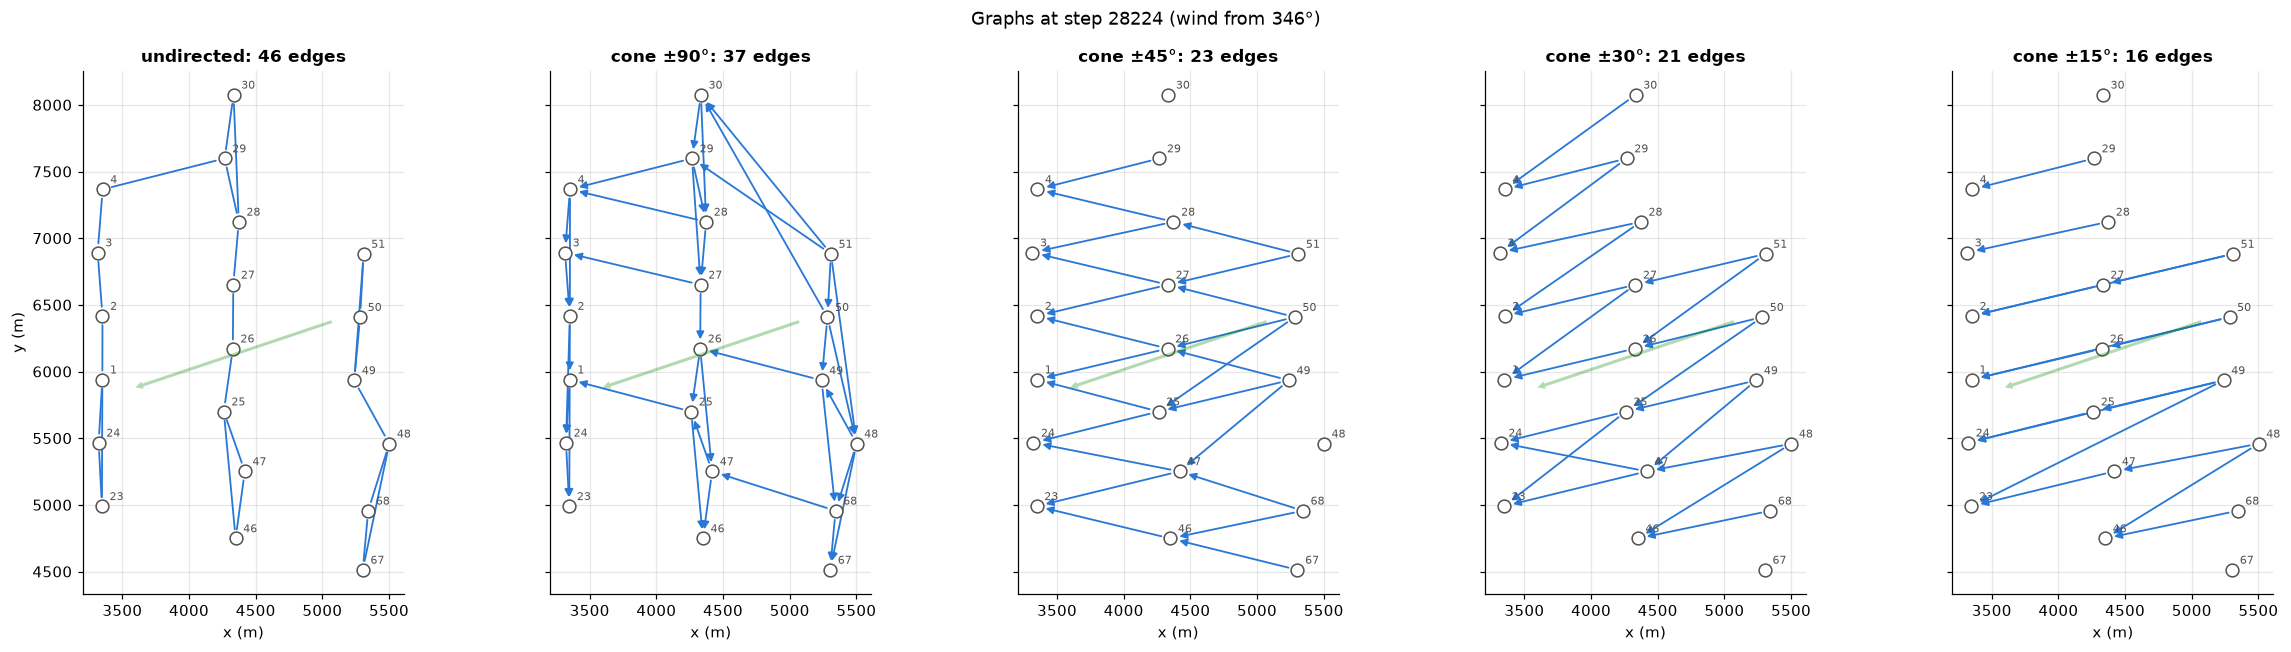

In [13]:
t_show = test_starts[0]
fig, axes = plt.subplots(1, 5, figsize=(22, 6), sharey=True)
for ax, (name, A) in zip(axes, GRAPHS.items()):
    At = A[t_show]
    for a, b in zip(*np.nonzero(At)):
        if name == "GNN undirected" and a > b:
            continue
        ax.annotate("", xy=turb_xy[b], xytext=turb_xy[a],
                    arrowprops=dict(arrowstyle="-" if name == "GNN undirected" else "-|>",
                                    color="#2a78d6", lw=1.2, shrinkA=6, shrinkB=6))
    ax.scatter(*turb_xy.T, s=70, color="white", edgecolor="#52514e", zorder=3)
    for k, tid in enumerate(W.columns):
        ax.annotate(str(tid), turb_xy[k], xytext=(5, 4), textcoords="offset points", fontsize=7, color="#52514e")
    c = turb_xy.mean(axis=0)
    ax.annotate("", xy=c + 800 * flow[t_show], xytext=c - 800 * flow[t_show],
                arrowprops=dict(arrowstyle="simple", color="#008300", alpha=0.3, lw=0))
    ax.set_title(f"{name.replace('GNN ', '')}: {int(At.sum())} edges")
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("y (m)")
fig.suptitle(f"Graphs at step {t_show} (wind from {wind_from[t_show]:.0f}°)")
plt.tight_layout()
plt.show()

## 6. Traditional methods

| Method | How a hidden turbine is filled |
|---|---|
| **Neighbour mean** | average of all reporting turbines at that step |
| **Last known value** | the turbine's own value just before the window, held constant |
| **Linear regression** | linear map from the snapshot (scaled wind, power, mask of all 20) to all 40 outputs |
| **MLP** | same inputs, 2 hidden layers of 128 (scikit-learn) |

**Why:** the first two need no training (the floor any model must beat). Linear regression and the MLP use the same inputs as the GNNs but no geometry or wind direction.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

def make_features(rows, vis):
    zw = np.where(vis, (w[rows] - w_mu) / w_sd, 0.0)
    zp = np.where(vis, (p[rows] - p_mu) / p_sd, 0.0)
    return np.hstack([zw, zp, vis.astype(float)])

def make_targets(rows):
    return np.hstack([(w[rows] - w_mu) / w_sd, (p[rows] - p_mu) / p_sd])

def unscale_flat(out):
    return out[:, :n_turb] * w_sd + w_mu, out[:, n_turb:] * p_sd + p_mu

def fill_neighbour_mean(rows, vis, prev):
    mean = lambda x: np.repeat(np.nanmean(np.where(vis, x[rows], np.nan), axis=1, keepdims=True), n_turb, axis=1)
    return mean(w), mean(p)

def fill_last_known(rows, vis, prev):
    return np.where(vis, w[rows], w[prev]), np.where(vis, p[rows], p[prev])

X_train, Y_train = make_features(train_rows, train_vis), make_targets(train_rows)

t0 = time.time()
linreg = LinearRegression().fit(X_train, Y_train)
print(f"linear regression: {time.time() - t0:.1f} s")

t0 = time.time()
mlp = MLPRegressor(hidden_layer_sizes=(128, 128), batch_size=256, early_stopping=True, max_iter=200,
                   random_state=0).fit(X_train, Y_train)
print(f"MLP: {time.time() - t0:.0f} s, {mlp.n_iter_} epochs, held-out R² = {mlp.best_validation_score_:.3f}")

def sk_fill(model):
    return lambda rows, vis, prev: unscale_flat(model.predict(make_features(rows, vis)))

linear regression: 0.2 s


MLP: 92 s, 76 epochs, held-out R² = 0.948


## 7. Neural models (PyTorch)

### 7.1 Shared training loop

**What:** one training routine for all PyTorch models: AdamW (lr 1e-3, weight decay 1e-4), batches of 256, loss = MSE on **hidden** turbines only, early stopping on the validation set (max 10 epochs, patience 3). Trained models are cached in `data/interim/v2_*.pt`; set `RETRAIN = True` to train again.

**Why:** identical training for every model, so differences come from the architecture and the graph.

In [15]:
import torch
from torch import nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH, MAX_EPOCHS, PATIENCE = 256, 10, 3
RETRAIN = False
MODEL_DIR = Path("../data/interim")
print(f"device: {DEVICE}")

def make_tokens(rows, vis):
    # (B, 20, 3): scaled wind, scaled power (0 where hidden), visible flag
    zw = np.where(vis, (w[rows] - w_mu) / w_sd, 0.0)
    zp = np.where(vis, (p[rows] - p_mu) / p_sd, 0.0)
    return torch.tensor(np.stack([zw, zp, vis], axis=-1), dtype=torch.float32, device=DEVICE)

def token_targets(rows):
    y = np.stack([(w[rows] - w_mu) / w_sd, (p[rows] - p_mu) / p_sd], axis=-1)
    return torch.tensor(y, dtype=torch.float32, device=DEVICE)

def hidden_mse(pred, target, vis):
    return ((pred - target) ** 2)[~torch.as_tensor(vis, device=DEVICE)].mean()

def fit(name, make_model, forward):
    # forward(model, rows, vis) -> (B, 20, 2) scaled prediction
    path = MODEL_DIR / f"v2_{name.lower().replace(' ', '_').replace('±', '').replace('°', '')}.pt"
    torch.manual_seed(0)
    model = make_model().to(DEVICE)
    if path.exists() and not RETRAIN:
        ckpt = torch.load(path, map_location=DEVICE)
        model.load_state_dict(ckpt["state"])
        model.eval()
        print(f"{name}: loaded ({ckpt['train_seconds']:.0f} s, {len(ckpt['history'])} epochs)")
        return model, ckpt["history"]

    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    gen = np.random.default_rng(0)
    history, best, best_state, bad, t0 = [], float("inf"), None, 0, time.time()
    for epoch in range(MAX_EPOCHS):
        model.train()
        order = gen.permutation(len(train_rows))
        for i in range(0, len(order), BATCH):
            b = order[i : i + BATCH]
            opt.zero_grad()
            hidden_mse(forward(model, train_rows[b], train_vis[b]), token_targets(train_rows[b]), train_vis[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            losses = [hidden_mse(forward(model, val_rows[i : i + 2048], val_vis[i : i + 2048]),
                                 token_targets(val_rows[i : i + 2048]), val_vis[i : i + 2048]).item()
                      for i in range(0, len(val_rows), 2048)]
        history.append(float(np.mean(losses)))
        if history[-1] < best - 1e-4:
            best, bad, best_state = history[-1], 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    secs = time.time() - t0
    torch.save({"state": model.state_dict(), "history": history, "train_seconds": secs}, path)
    print(f"{name}: trained in {secs:.0f} s, {len(history)} epochs, best val MSE {best:.4f}")
    return model, history

def torch_fill(model, forward):
    def fill(rows, vis, prev):
        with torch.no_grad():
            out = np.concatenate([forward(model, rows[i : i + 2048], vis[i : i + 2048]).cpu().numpy()
                                  for i in range(0, len(rows), 2048)])
        return out[..., 0] * w_sd + w_mu, out[..., 1] * p_sd + p_mu
    return fill

histories = {}

device: cpu


### 7.2 Transformer

**What:** the draft's Transformer: one token per turbine (wind, power, mask) plus a turbine embedding and position. 3 attention layers, and only reporting turbines can be attended to.

**Why:** a strong non-graph model. Attention lets every turbine pick its own neighbours, like a learned fully connected graph.

In [16]:
class AttentionBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, h, hidden):
        z = self.norm1(h)
        a, _ = self.attn(z, z, z, key_padding_mask=hidden, need_weights=False)
        h = h + self.drop(a)
        return h + self.drop(self.ff(self.norm2(h)))


class ImputationTransformer(nn.Module):
    def __init__(self, d_model=64, n_heads=4, n_layers=3, d_ff=128, dropout=0.1):
        super().__init__()
        self.embed_input = nn.Linear(3, d_model)
        self.embed_turbine = nn.Embedding(n_turb, d_model)
        self.embed_position = nn.Linear(2, d_model)
        self.register_buffer("xy", torch.tensor(turb_xy_km, dtype=torch.float32))
        self.blocks = nn.ModuleList(AttentionBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers))
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 2)

    def forward(self, tokens):
        hidden = tokens[..., 2] < 0.5
        h = self.embed_input(tokens) + self.embed_turbine.weight + self.embed_position(self.xy)
        for block in self.blocks:
            h = block(h, hidden)
        return self.head(self.norm(h))


fwd_tf = lambda m, rows, vis: m(make_tokens(rows, vis))
transformer, histories["Transformer"] = fit("Transformer", ImputationTransformer, fwd_tf)

Transformer: loaded (201 s, 10 epochs)


### 7.3 MAF-GNN (paper model, simplified)

Zhang et al. (2026), *Information* 17(7):699. No code is published, so the three modules are rebuilt from the paper and adapted from forecasting to gap filling.

| Paper module | Here |
|---|---|
| **MARL**: one encoder per modality, learnable placeholder for a missing modality, cross-modal attention, gated fusion | same; 5 modalities: wind speed, power, wind direction (sin, cos), temperature difference, pitch. A hidden turbine has all modalities missing, so it gets the placeholders. |
| **AGL-MS**: learned mix of cosine, DTW, MIC and geographic similarity | cosine + geographic (Gaussian kernel) + **Pearson correlation** of training power. DTW and MIC are left out (too slow for CPU); correlation stands in for MIC. |
| **CM-GCN**: credibility score per turbine weights its messages, 2 layers | same |
| History window (T steps), LSTM decoder | single snapshot (T = 1), MLP decoder, so it sees the same time span as the other models |

**Deviation:** a learned turbine embedding is added, otherwise all hidden turbines would start identical. The paper's graph is dense (all 20 turbines), so it is not limited to 2 neighbours.

In [17]:
wdir_rel = np.deg2rad(wide("Wdir").to_numpy())
MODAL = [w, p, np.sin(wdir_rel), np.cos(wdir_rel), wide("Tdiff").to_numpy(), wide("Pab1").to_numpy()]
modal_mu = [np.nanmean(x[tr]) for x in MODAL]
modal_sd = [np.nanstd(x[tr]) + 1e-6 for x in MODAL]
MODAL_GROUPS = [[0], [1], [2, 3], [4], [5]]          # wind speed, power, direction, temp. difference, pitch

def make_modalities(rows, vis):
    z = [np.nan_to_num((x[rows] - m) / s) for x, m, s in zip(MODAL, modal_mu, modal_sd)]
    return [torch.tensor(np.stack([z[i] * vis for i in g], axis=-1), dtype=torch.float32, device=DEVICE)
            for g in MODAL_GROUPS]

sigma = np.median(pair_dist[pair_dist > 0])
S_GEO = np.exp(-pair_dist**2 / (2 * sigma**2))
S_CORR = np.clip(np.corrcoef(p[tr].T), 0, 1)


class MAFGNN(nn.Module):
    def __init__(self, d=64, heads=4, tau=1.0, dropout=0.1):
        super().__init__()
        dims = [len(g) for g in MODAL_GROUPS]
        F = len(dims)
        self.encoders = nn.ModuleList(nn.Sequential(nn.Linear(dm, d), nn.GELU()) for dm in dims)
        self.placeholder = nn.Parameter(0.02 * torch.randn(F, d))          # MARL: missing-modality embedding
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)      # cross-modal attention
        self.gate = nn.Sequential(nn.Linear(F * d, d), nn.GELU(), nn.Linear(d, F))
        self.tau = tau
        self.fuse = nn.Sequential(nn.Linear(3 * d, d), nn.GELU(), nn.Linear(d, d))
        self.norm, self.drop = nn.LayerNorm(d), nn.Dropout(dropout)
        self.embed_turbine = nn.Embedding(n_turb, d)
        self.sim_logits = nn.Parameter(torch.zeros(3))                      # AGL-MS: cosine, geographic, correlation
        self.register_buffer("s_geo", torch.tensor(S_GEO, dtype=torch.float32))
        self.register_buffer("s_corr", torch.tensor(S_CORR, dtype=torch.float32))
        self.credibility = nn.Linear(d, 1)                                  # CM-GCN
        self.gcn = nn.ModuleList(nn.Linear(d, d) for _ in range(2))
        self.head = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Linear(d, 2))

    def forward(self, mods, vis):
        z = torch.stack([enc(x) for enc, x in zip(self.encoders, mods)], dim=2)          # (B, N, F, d)
        z = torch.where(vis[..., None, None], z, self.placeholder)
        B, N, F, d = z.shape
        m = z.reshape(B * N, F, d)
        a, _ = self.attn(m, m, m, need_weights=False)
        g = torch.softmax(self.gate(a.flatten(1)) / self.tau, dim=-1)[..., None]
        f = torch.cat([(g * a).sum(1), (g * m).sum(1), a.sum(1)], dim=-1)
        h = self.norm(self.drop(self.fuse(f))).reshape(B, N, d) + self.embed_turbine.weight

        hn = torch.nn.functional.normalize(h, dim=-1)
        c = torch.softmax(self.sim_logits, dim=0)
        A = c[0] * (hn @ hn.transpose(1, 2) + 1) / 2 + c[1] * self.s_geo + c[2] * self.s_corr   # A[b, i, j]: j -> i
        A = A / A.sum(-1, keepdim=True)
        S = torch.sigmoid(self.credibility(h))                                            # (B, N, 1)
        weight = A * S.transpose(1, 2)
        for lin in self.gcn:
            h = torch.nn.functional.gelu((weight @ lin(h)) / (weight.sum(-1, keepdim=True) + 1e-6))
        return self.head(h)


fwd_maf = lambda m, rows, vis: m(make_modalities(rows, vis), torch.as_tensor(vis, device=DEVICE))
maf, histories["MAF-GNN (paper)"] = fit("MAF-GNN", MAFGNN, fwd_maf)
c = torch.softmax(maf.sim_logits, 0).tolist()
print(f"learned similarity weights: cosine {c[0]:.2f}, geographic {c[1]:.2f}, correlation {c[2]:.2f}")

MAF-GNN: loaded (329 s, 10 epochs)
learned similarity weights: cosine 0.16, geographic 0.72, correlation 0.11


### 7.4 GATv2 on the five graphs

**What:** the draft's graph-attention model with **2 layers** (= 2 hops): embedding (input + turbine + position), 2 GATv2 blocks with 4 heads, read-out of wind and power. Edge features: distance and x/y offset (km). Each turbine keeps its own information through a self-loop. One model is trained per graph.

**Why:** the model is identical across graphs, so any difference comes from **which edges exist** (RQ2).

In [18]:
from torch_geometric.nn import GATv2Conv

def edges(A):
    # A: (B, 20, 20) bool, a -> b. Returns edge_index, edge_attr for one big batched graph.
    bb, src, dst = np.nonzero(A)
    edge_index = torch.tensor(np.stack([bb * n_turb + src, bb * n_turb + dst]), device=DEVICE)
    edge_attr = torch.tensor(edge_geom[src, dst], device=DEVICE)
    return edge_index, edge_attr


class GraphBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.conv = GATv2Conv(d_model, d_model // n_heads, heads=n_heads, edge_dim=3, dropout=dropout)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, h, edge_index, edge_attr):
        h = h + self.drop(self.conv(self.norm1(h), edge_index, edge_attr))
        return h + self.drop(self.ff(self.norm2(h)))


class GATImputer(nn.Module):
    def __init__(self, d_model=64, n_heads=4, n_layers=2, d_ff=128, dropout=0.1):
        super().__init__()
        self.embed_input = nn.Linear(3, d_model)
        self.embed_turbine = nn.Embedding(n_turb, d_model)
        self.embed_position = nn.Linear(2, d_model)
        self.register_buffer("xy", torch.tensor(turb_xy_km, dtype=torch.float32))
        self.blocks = nn.ModuleList(GraphBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers))
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 2)

    def forward(self, tokens, edge_index, edge_attr):
        B = tokens.shape[0]
        h = self.embed_input(tokens) + self.embed_turbine.weight + self.embed_position(self.xy)
        h = h.reshape(B * n_turb, -1)
        for block in self.blocks:
            h = block(h, edge_index, edge_attr)
        return self.head(self.norm(h)).reshape(B, n_turb, 2)


gnns, fwd_gnn = {}, {}
for name, A in GRAPHS.items():
    fwd_gnn[name] = lambda m, rows, vis, A=A: m(make_tokens(rows, vis), *edges(A[rows]))
    gnns[name], histories[name] = fit(name, GATImputer, fwd_gnn[name])

C:\Users\edwar\Git_repo\GML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\edwar\Git_repo\GML\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


GNN undirected: loaded (215 s, 10 epochs)
GNN cone ±90°: loaded (183 s, 10 epochs)
GNN cone ±45°: loaded (79 s, 4 epochs)
GNN cone ±30°: loaded (73 s, 4 epochs)
GNN cone ±15°: loaded (111 s, 6 epochs)


## 8. Results

### 8.1 Error by hidden share

**What:** fill the test windows with every method at each hidden share, and compute MAE over the hidden values. `all` pools the four shares.

**Why:** the main comparison for both research questions.

In [19]:
METHODS = {
    "Neighbour mean": fill_neighbour_mean,
    "Last known value": fill_last_known,
    "Linear regression": sk_fill(linreg),
    "MLP": sk_fill(mlp),
    "Transformer": torch_fill(transformer, fwd_tf),
    "MAF-GNN (paper)": torch_fill(maf, fwd_maf),
    **{name: torch_fill(gnns[name], fwd_gnn[name]) for name in GRAPHS},
}
GNN_METHODS = ["MAF-GNN (paper)", *GRAPHS]

# per hidden value: was a reporting turbine reachable within 2 hops in that GNN's graph?
reach = {name: two_hop(A[test_rows]) for name, A in GRAPHS.items()}

parts = []
for share, vis in TEST_VIS.items():
    hid = ~vis
    win = np.broadcast_to(test_window[:, None], vis.shape)[hid]
    for m, fill in METHODS.items():
        fw, fp = fill(test_rows, vis, test_prev)
        covered = ((reach[m] & vis[:, :, None]).any(axis=1)[hid] if m in reach else np.full(hid.sum(), True))
        parts.append(pd.DataFrame({
            "share": f"{share:.0%}", "method": m, "window": win, "covered": covered,
            "w_err": np.abs(fw - w[test_rows])[hid], "p_err": np.abs(fp - p[test_rows])[hid],
        }))
errs = pd.concat(parts, ignore_index=True)

def mae_table(df):
    g = pd.concat([df, df.assign(share="all")]).groupby(["method", "share"], sort=False)
    t = pd.concat({"Wspd MAE (m/s)": g["w_err"].mean().round(3).unstack("share"),
                   "Patv MAE (kW)": g["p_err"].mean().round(1).unstack("share")}, axis=1)
    return t.reindex(list(METHODS))

SHARE_LABELS = [f"{s:.0%}" for s in HIDDEN_SHARES]
results = mae_table(errs)
results.style.highlight_min(axis=0, props="font-weight: bold")

**What:** MAE against hidden share. Left: RQ1 (traditional methods, the Transformer, the paper model and the best of our GNNs). Right: RQ2 (our five graphs).

**Why:** shows how each method degrades as fewer turbines report.

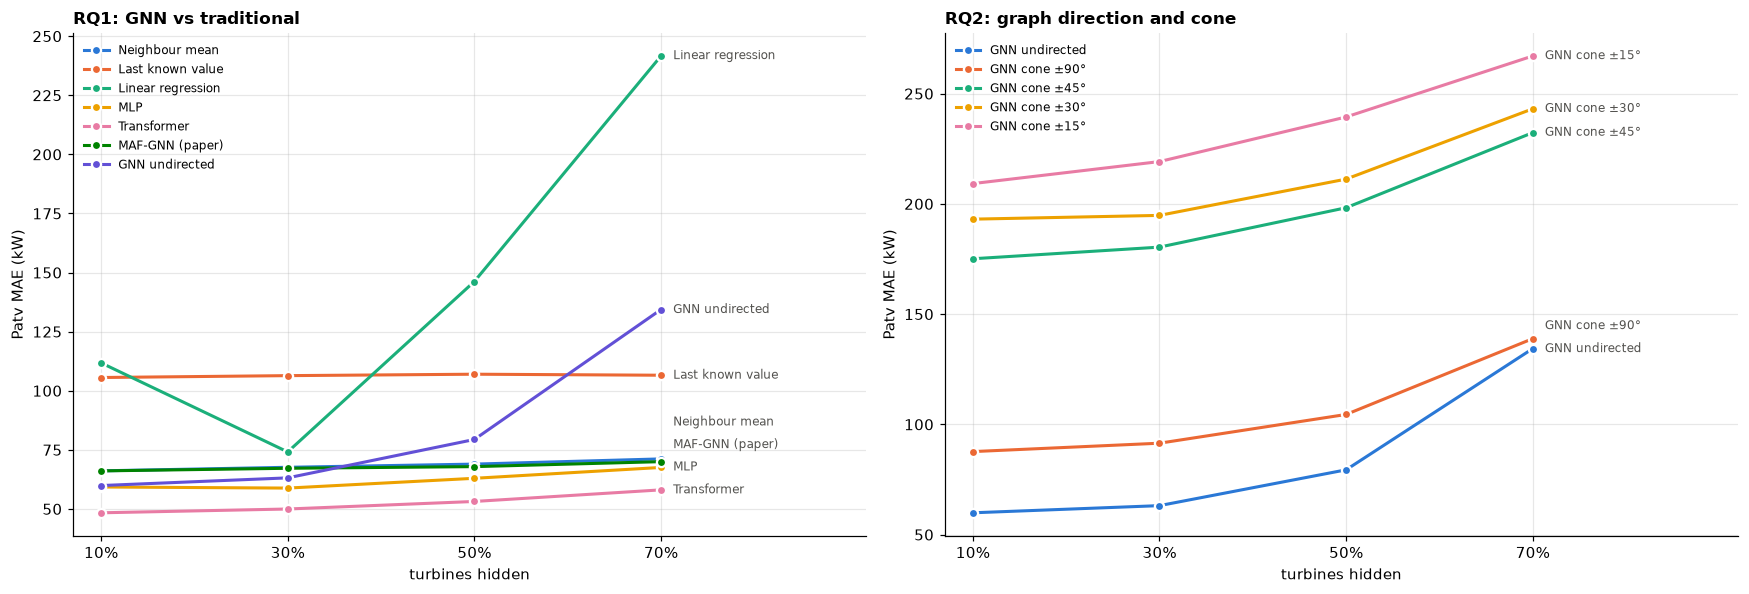

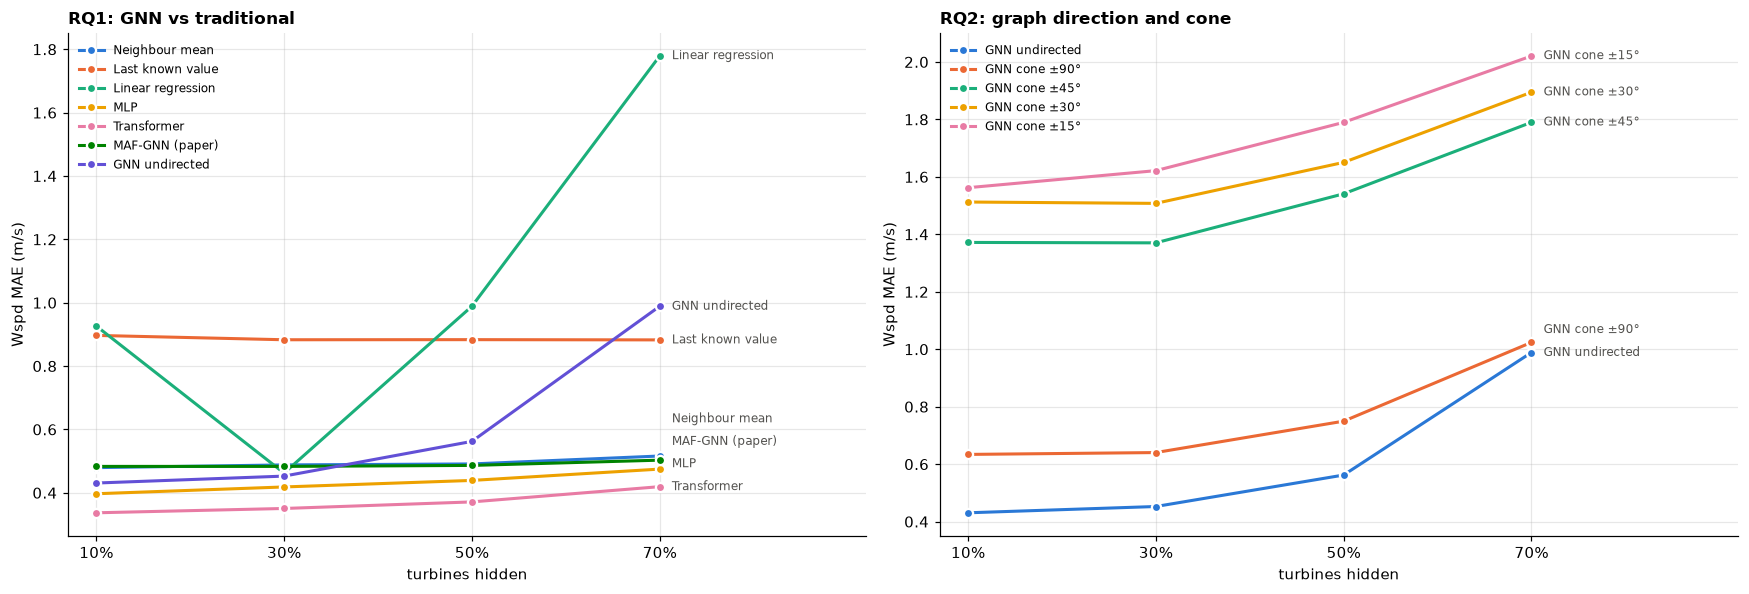

In [20]:
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
by_share = errs.groupby(["method", "share"])[["w_err", "p_err"]].mean()
best_ours = by_share.loc[list(GRAPHS), "p_err"].groupby("method").mean().idxmin()
groups = {
    "RQ1: GNN vs traditional": ["Neighbour mean", "Last known value", "Linear regression", "MLP",
                                "Transformer", "MAF-GNN (paper)", best_ours],
    "RQ2: graph direction and cone": list(GRAPHS),
}
x = [100 * s for s in HIDDEN_SHARES]
for metric, label in [("p_err", "Patv MAE (kW)"), ("w_err", "Wspd MAE (m/s)")]:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    for ax, (title, ms) in zip(axes, groups.items()):
        ends = []
        for k, m in enumerate(ms):
            y = by_share.loc[m, metric].to_numpy()
            ax.plot(x, y, "-o", color=SERIES[k], lw=2, ms=6, mec="white", mew=1.5, label=m)
            ends.append([y[-1], m])
        # direct labels at the line ends, nudged apart so they do not overlap
        lo, hi = ax.get_ylim()
        ends.sort()
        for j in range(1, len(ends)):
            ends[j][0] = max(ends[j][0], ends[j - 1][0] + 0.045 * (hi - lo))
        for y_end, m in ends:
            ax.annotate(m, (x[-1], y_end), xytext=(8, 0), textcoords="offset points", va="center",
                        fontsize=8, color="#52514e")
        ax.set_xticks(x, [f"{v:.0f}%" for v in x])
        ax.set_xlim(x[0] - 3, x[-1] + 22)
        ax.set_xlabel("turbines hidden")
        ax.set_ylabel(label)
        ax.set_title(title, loc="left")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(fontsize=8, frameon=False, loc="upper left")
    plt.tight_layout()
    plt.show()

### 8.2 RQ1: is the best GNN significantly better?

**What:** compare the best GNN with the best non-graph method (lowest pooled power MAE) per hidden share. 95% confidence interval of the MAE difference from a paired bootstrap over test windows (2,000 resamples).

**Why:** the windows are a sample, so the result needs an uncertainty. An interval that excludes 0 means a real difference. Note that both "best" models are chosen on the test set, which slightly favours them.

In [21]:
pooled = errs.groupby("method")["p_err"].mean()
best_gnn = pooled[GNN_METHODS].idxmin()
best_other = pooled.drop(GNN_METHODS).idxmin()

boot_rng = np.random.default_rng(0)
rows_ci = []
for share in [*SHARE_LABELS, "all"]:
    sub = errs if share == "all" else errs[errs["share"] == share]
    per = sub[sub["method"].isin([best_gnn, best_other])].groupby(["method", "share", "window"])[["w_err", "p_err"]].agg(["sum", "count"])
    for metric, unit in [("p_err", "kW"), ("w_err", "m/s")]:
        a = per.loc[best_gnn, (metric, "sum")].to_numpy()
        b = per.loc[best_other, (metric, "sum")].to_numpy()
        n = per.loc[best_gnn, (metric, "count")].to_numpy()
        idx = boot_rng.integers(0, len(a), size=(2000, len(a)))
        diff = (a[idx].sum(1) - b[idx].sum(1)) / n[idx].sum(1)
        rows_ci.append({"share": share, "metric": f"MAE ({unit})",
                        "difference": round((a.sum() - b.sum()) / n.sum(), 3),
                        "95% CI": f"[{np.percentile(diff, 2.5):.3f}, {np.percentile(diff, 97.5):.3f}]"})
print(f"best GNN: {best_gnn} | best non-graph: {best_other} | difference = GNN minus non-graph (negative = GNN better)")
pd.DataFrame(rows_ci).pivot(index="share", columns="metric", values=["difference", "95% CI"])

best GNN: MAF-GNN (paper) | best non-graph: Transformer | difference = GNN minus non-graph (negative = GNN better)


difference                      95% CI                
metric   MAE (kW) MAE (m/s)          MAE (kW)       MAE (m/s)
share                                                        
10%        17.721     0.146  [14.450, 20.963]  [0.126, 0.168]
30%        17.227     0.133  [14.918, 19.681]  [0.120, 0.147]
50%        14.738     0.115  [12.840, 16.668]  [0.105, 0.127]
70%        11.939     0.084  [10.332, 13.573]  [0.074, 0.093]
all        14.167     0.107  [13.110, 15.247]  [0.101, 0.113]

### 8.3 RQ2: direction, cone width and coverage

**What:** for each of our graphs: share of hidden values with at least one **reporting** turbine within 2 hops, and the power MAE for hidden values with and without such a turbine.

**Why:** a narrow cone is more physically targeted but leaves more turbines with nobody to listen to. This separates "the graph is wrong" from "the graph is empty".

In [22]:
rows_cov = []
for name in GRAPHS:
    e = errs[errs["method"] == name]
    for share in [*SHARE_LABELS, "all"]:
        s = e if share == "all" else e[e["share"] == share]
        rows_cov.append({"graph": name, "share": share,
                         "covered": f"{s['covered'].mean():.0%}",
                         "MAE covered (kW)": round(s.loc[s["covered"], "p_err"].mean(), 1),
                         "MAE not covered (kW)": round(s.loc[~s["covered"], "p_err"].mean(), 1)})
coverage = pd.DataFrame(rows_cov).set_index(["graph", "share"])
coverage.unstack("share").reindex(columns=[*SHARE_LABELS, "all"], level=1)

covered                     MAE covered (kW)                \
share              10%  30%  50%  70%  all              10%    30%    50%   
graph                                                                       
GNN cone ±15°      55%  51%  42%  30%  39%             90.5   97.5   97.0   
GNN cone ±30°      62%  61%  54%  41%  50%            101.8  104.4  108.8   
GNN cone ±45°      68%  66%  59%  46%  55%             97.3  100.8  104.4   
GNN cone ±90°      95%  94%  89%  74%  84%             75.2   76.4   79.0   
GNN undirected    100%  99%  96%  79%  90%             59.9   61.5   67.4   

                             MAE not covered (kW)                              
share             70%    all                  10%    30%    50%    70%    all  
graph                                                                          
GNN cone ±15°   100.3   97.7                351.7  345.2  342.7  338.1  341.2  
GNN cone ±30°   117.4  110.4                339.3  334.7  331.7  331.9  332.6  
GNN cone ±45°   112.9  106.2                337.4  334.5  331.1  332.0  332.3  
GNN cone ±90°    81.6   79.2                308.5  307.9  303.6  302.6  303.3  
GNN undirected   73.8   68.1                  NaN  373.6  352.9  366.4  364.8

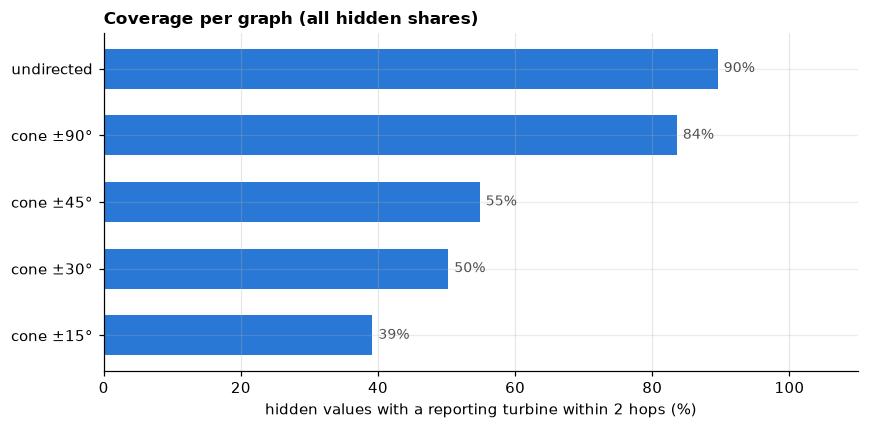

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
cov_all = [errs.loc[(errs["method"] == g), "covered"].mean() * 100 for g in GRAPHS]
labels = [g.replace("GNN ", "") for g in GRAPHS]
bars = ax.barh(labels, cov_all, color="#2a78d6", height=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=4, color="#52514e", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xlabel("hidden values with a reporting turbine within 2 hops (%)")
ax.set_title("Coverage per graph (all hidden shares)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Conclusions and recommendations

Numbers are pooled power MAE over all hidden shares (Section 8.1), unless stated.

### RQ1: are GNNs better than traditional methods? **No, not here.**

| Rank | Method | Patv MAE (kW) | Wspd MAE (m/s) |
|---|---|---|---|
| 1 | Transformer | **54.4** | **0.386** |
| 2 | MLP | 64.0 | 0.448 |
| 3 | MAF-GNN (paper) | 68.6 | 0.493 |
| 4 | Neighbour mean | 69.5 | 0.501 |
| 5 | GNN undirected | 99.2 | 0.720 |
| – | Last known value / linear regression / cone GNNs | 107–246 | 0.84–1.85 |

- **Best GNN (MAF-GNN) is 14 kW worse than the Transformer**, 95% CI [13, 15] kW, so the difference is significant. It barely beats the neighbour mean: it learned mostly the geographic prior (weight 0.72) and smooths over all turbines.
- **GNN undirected has only within-column edges**: each turbine's 2 nearest neighbours sit in its own column (474 m apart vs 991 m between columns), so the three columns are cut off from each other (Section 5.2).
- **GNN undirected is competitive only when few turbines are missing** (10% hidden: 59.9 kW, the same as the MLP). It falls apart at 70% hidden (134 kW), when coverage drops to 79%.
- **Linear regression is not suitable.** It cannot handle a changing set of missing inputs, and is worse than the neighbour mean at every share.

### RQ2: does a directed, wind-following graph help? **No. Narrower is worse.**

| Graph | Patv MAE (kW) | Hidden values covered within 2 hops | MAE if covered | MAE if not covered |
|---|---|---|---|---|
| Undirected | **99.2** | 90% | 68 | 365 |
| Cone ±90° | 116.0 | 84% | 79 | 303 |
| Cone ±45° | 208.4 | 55% | 106 | 332 |
| Cone ±30° | 221.0 | 50% | 110 | 333 |
| Cone ±15° | 245.8 | 39% | 98 | 341 |

- **Error grows steadily as the cone narrows**: 116 → 208 → 221 → 246 kW (±90° → ±15°).
- **±90° (the whole upwind side) comes close but does not beat undirected**: 116 vs 99 kW overall, and nearly equal at 70% hidden (139 vs 134 kW). Only 5% of turbines are front row and coverage rises to 84%.
- **Coverage drives the result.** With cones of ±45° or narrower, 29–43% of turbines have no upwind neighbour at all. Those hidden turbines can only guess the average (≈ 340 kW error).
- **Even when covered, upwind-only is worse** (79–110 vs 68 kW). When the wind blows across the columns, the cones skip the same-column neighbours, which are the closest and most similar turbines. The neighbours on the side and downwind carry useful information too. At this farm, power correlation stays above 0.88 at every distance, and wake losses are small (notebook 02), so wind direction says little about *which* neighbour is informative.

### Recommendations

1. **For gap filling at this farm, use the Transformer.** It's best at every hidden share: 22% lower power error than the neighbour mean, 15% lower than the MLP. Attention acts as a learned, fully connected graph.
2. **If a GNN is required, connect it densely**: more neighbours (e.g. k = 6–8 or a 1500 m radius, as in the draft) or a fallback edge to the nearest reporting turbine. Two neighbours is too sparse once turbines go missing.
3. **Use wind direction as an edge feature, not as a filter.** Hard upwind-only edges remove useful information; a feature lets the model learn how much direction matters.
4. **Follow-up experiments:** (a) cone graphs with more neighbours plus a fallback edge, to separate *direction* from *coverage*; (b) a reversed-cone control; (c) 3 seeds and longer training (the Transformer and MAF-GNN were still improving at the 10-epoch cap); (d) a history window (the turbine's own last values).

**Limitations:** one seed per model; 10-epoch cap; MAF-GNN simplified (no DTW/MIC, single snapshot) and given more inputs than the other models; the 20-turbine patch only; the best GNN and best non-graph model in 8.2 were chosen on the test set.

## 10. Rubric check

| Criterion | Covered in this notebook | Still needed (mostly in the report) |
|---|---|---|
| **Design & context (15%)** | Two research questions with clear hypotheses; paper model (MAF-GNN) as the graph-ML reference; graph choices justified | Literature context in the report: MAF-GNN, GATv2, wake-based / directed graphs, imputation with GNNs; the gap this project tests |
| **Implementation (15%)** | Simple baselines (neighbour mean, last known value), traditional (linear regression, MLP), advanced (Transformer, MAF-GNN, 4 GNN graphs), all on the same test windows | More seeds; the dense / fallback GNN variants (recommendation 2) |
| **Analysis (20%)** | Sensitivity to hidden share (10–70%), significance by paired bootstrap, coverage analysis explaining RQ2, follow-up directions | An ablation of the MAF-GNN modules (similarity priors, credibility) would strengthen this |
| **Challenges (10%)** | Dynamic graphs (edges change with the wind); missing node features (masked turbines, MAF-GNN placeholders); limited receptive field / isolated nodes (front-row turbines); over-smoothing in a dense graph (MAF-GNN ≈ neighbour mean) | Discuss each briefly in the report, in the context of these results |
| **Knock-out** | – | Report clearly written, **max 5 pages** excluding references |